# [핸즈온 머신러닝] Chapter 4 – 모델 훈련 (Training Models)

<table align="left">
  <td>
    <a href="https://colab.research.google.com/github/jsmak/handson-mlp-study/blob/main/ch04/04_training_linear_models_kr.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>
  </td>
</table>
<br clear="left"/>

> **📚 출처 및 라이선스**
>
> - **원본 노트북**: [rickiepark/handson-mlp](https://github.com/rickiepark/handson-mlp) – [`04_training_linear_models.ipynb`](https://github.com/rickiepark/handson-mlp/blob/main/04_training_linear_models.ipynb) (박해선 님, 『핸즈온 머신러닝 with 사이킷런, 파이토치』 한빛미디어, 2026 예제 코드)
> - **원저작**: [ageron/handson-mlp](https://github.com/ageron/handson-mlp) (Aurélien Géron, *Hands-On Machine Learning with Scikit-Learn and PyTorch*, O'Reilly)
> - **라이선스**: 원본 코드는 [Apache License 2.0](https://github.com/rickiepark/handson-mlp/blob/main/LICENSE)을 따릅니다.
> - **변경 사항**: 개인 학습(인프런 챌린지 복습) 목적으로 원본 노트북을 바탕으로 한국어 설명·주석을 추가하고, 셀 구성을 책의 절 번호에 맞춰 재정리했습니다. 책 본문은 포함하지 않습니다.

선형 회귀를 **정규 방정식**과 **경사 하강법**으로 훈련해 보고, 다항 회귀·학습 곡선·규제·로지스틱 회귀·소프트맥스 회귀까지 살펴봅니다.

| 절 | 내용 | 주요 코드 |
|---|---|---|
| 4.1 | 선형 회귀 (정규 방정식, SVD) | `np.linalg.inv`, `LinearRegression`, `np.linalg.lstsq`, `np.linalg.pinv` |
| 4.2 | 경사 하강법 (배치 / 확률적 / 미니배치) | 직접 구현, `SGDRegressor` |
| 4.3 | 다항 회귀 | `PolynomialFeatures` |
| 4.4 | 학습 곡선 | `learning_curve` |
| 4.5 | 규제가 있는 선형 모델 | `Ridge`, `Lasso`, `ElasticNet`, 조기 종료 |
| 4.6 | 로지스틱 회귀 · 소프트맥스 회귀 | `LogisticRegression` |

## **4.1 선형 회귀**

선형 회귀 모델은 입력 특성의 가중치 합에 편향(bias)을 더해 예측합니다.

$$\hat{y} = h_{\boldsymbol{\theta}}(\mathbf{x}) = \boldsymbol{\theta}^{\mathrm{T}} \mathbf{x} = \theta_0 + \theta_1 x_1 + \cdots + \theta_n x_n$$

훈련이란 비용 함수 MSE를 최소화하는 $\boldsymbol{\theta}$를 찾는 것입니다.

### **4.1.1 정규 방정식**

비용 함수를 최소화하는 $\boldsymbol{\theta}$를 바로 구하는 공식(닫힌 형태의 해)입니다.

$$\hat{\boldsymbol{\theta}} = (\mathbf{X}^{\mathrm{T}} \mathbf{X})^{-1} \mathbf{X}^{\mathrm{T}} \mathbf{y}$$

$y = 4 + 3x_1 + \text{가우스 잡음}$으로 선형처럼 보이는 데이터 200개를 만듭니다.

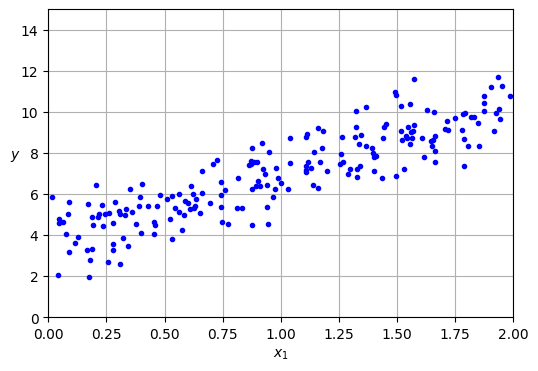

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(seed=42)
m = 200  # 샘플 개수
X = 2 * rng.random((m, 1))  # 열벡터
y = 4 + 3 * X + rng.standard_normal((m, 1))  # 열벡터

plt.figure(figsize=(6, 4))
plt.plot(X, y, "b.")
plt.xlabel("$x_1$")
plt.ylabel("$y$", rotation=0)
plt.axis([0, 2, 0, 15])
plt.grid()
plt.show()

`add_dummy_feature()`로 $x_0 = 1$을 추가하고 정규 방정식으로 $\hat{\boldsymbol{\theta}}$를 계산합니다. 잡음 때문에 원래 값(4, 3)과 약간 다릅니다.

y= [3.32960458] x +  [3.69084138]
[[ 3.69084138]
 [10.35005055]]


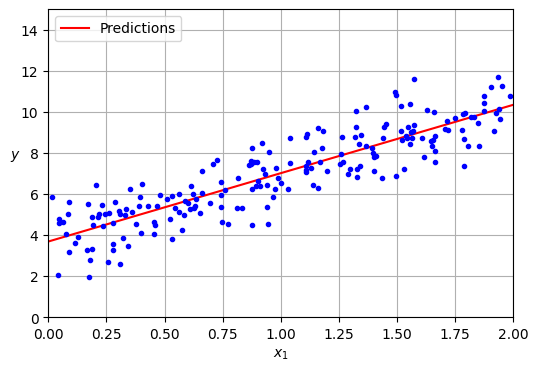

In [2]:
from sklearn.preprocessing import add_dummy_feature

X_b = add_dummy_feature(X)  # 각 샘플에 x0 = 1 추가
theta_best = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y
print("y=", theta_best[1], "x + ", theta_best[0])  # y= [3.32960458] x +  [3.69084138]
X_new = np.array([[0], [2]])
X_new_b = add_dummy_feature(X_new)  # 각 샘플에 x0 = 1 추가
y_predict = X_new_b @ theta_best
print(y_predict)  # x=0, x=2에서의 예측

plt.figure(figsize=(6, 4))  # 그래프 크기 지정 (필수 아님)
plt.plot(X_new, y_predict, "r-", label="Predictions")
plt.plot(X, y, "b.")

# 그래프 꾸미기
plt.xlabel("$x_1$")
plt.ylabel("$y$", rotation=0)
plt.axis([0, 2, 0, 15])
plt.grid()
plt.legend(loc="upper left")

plt.show()

사이킷런 `LinearRegression`, `np.linalg.lstsq()`, 유사역행렬 `np.linalg.pinv()`도 모두 같은 결과를 냅니다. (SVD 기반이라 $\mathbf{X}^{\mathrm{T}}\mathbf{X}$의 역행렬이 없어도 계산 가능)

In [3]:
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()
lin_reg.fit(X, y)
print("y=", lin_reg.coef_[0], "x + ", lin_reg.intercept_)  # 가중치(coef_)와 편향(intercept_)을 따로 저장
print(lin_reg.predict(X_new))

# LinearRegression이 내부적으로 사용하는 최소 제곱 함수
theta_best_svd, residuals, rank, s = np.linalg.lstsq(X_b, y, rcond=1e-6)
print("y=", theta_best_svd[1], "x + ", theta_best_svd[0])

# 유사역행렬(pseudoinverse)로 직접 계산: θ = X⁺y
theta_pinv = np.linalg.pinv(X_b) @ y
print("y=", theta_pinv[1], "x + ", theta_pinv[0])

y= [3.32960458] x +  [3.69084138]
[[ 3.69084138]
 [10.35005055]]
y= [3.32960458] x +  [3.69084138]
y= [3.32960458] x +  [3.69084138]


### **4.1.2 계산 복잡도**

| 방법 | 특성 수 $n$에 대한 복잡도 | 특성 수 2배 → |
|---|---|---|
| 정규 방정식 ($(\mathbf{X}^{\mathrm{T}}\mathbf{X})^{-1}$) | 약 $O(n^3)$ (구현에 따라 다름) | 약 $2^3 = 8$배 |
| SVD (`LinearRegression`) | 약 $O(n^2)$ | 약 4배 |

두 방법 모두 훈련 샘플 수 $m$에는 선형적이고, 훈련된 모델의 예측은 매우 빠릅니다. (코드 없음)

## **4.2 경사 하강법**

비용 함수의 그레이디언트(기울기)를 계산해 기울기가 감소하는 방향으로 파라미터를 조금씩 반복해서 조정합니다.

$$\boldsymbol{\theta}^{(\text{next step})} = \boldsymbol{\theta} - \eta \nabla_{\boldsymbol{\theta}} \text{MSE}(\boldsymbol{\theta})$$

### **4.2.1 배치 경사 하강법**

배치 경사 하강법을 직접 구현합니다. 매 스텝 **전체 훈련 세트**로 그레이디언트 $\frac{2}{m}\mathbf{X}^{\mathrm{T}}(\mathbf{X}\boldsymbol{\theta} - \mathbf{y})$를 계산합니다.

In [4]:
import matplotlib as mpl

eta = 0.1     # 학습률
n_epochs = 1000
m = len(X_b)  # 샘플 개수

rng = np.random.default_rng(seed=42)
theta = rng.standard_normal((2, 1))  # 모델 파라미터를 랜덤하게 초기화

for epoch in range(n_epochs):
    gradients = 2 / m * X_b.T @ (X_b @ theta - y)
    theta = theta - eta * gradients
print("y=", theta[1], "x + ", theta[0])  # 정규 방정식과 같은 결과

y= [3.32960458] x +  [3.69084138]


학습률 $\eta$ 세 가지(0.02, 0.1, 0.5)로 첫 20스텝을 비교합니다. 왼쪽은 너무 느리고, 가운데는 적당하며, 오른쪽은 발산합니다.

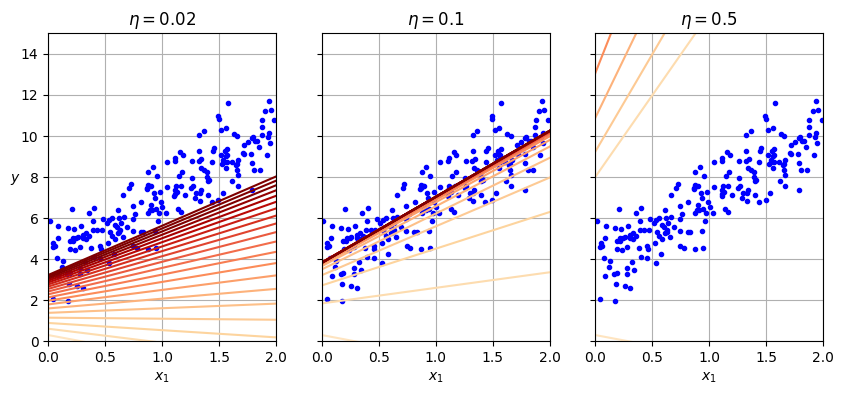

In [5]:
def plot_gradient_descent(theta, eta):
    m = len(X_b)
    plt.plot(X, y, "b.")
    n_epochs = 1000
    n_shown = 20
    theta_path = []
    for epoch in range(n_epochs):
        if epoch < n_shown:
            y_predict = X_new_b @ theta
            color = mpl.colors.rgb2hex(plt.cm.OrRd(epoch / n_shown + 0.15))
            plt.plot(X_new, y_predict, linestyle="solid", color=color)
        gradients = 2 / m * X_b.T @ (X_b @ theta - y)
        theta = theta - eta * gradients
        theta_path.append(theta)
    plt.xlabel("$x_1$")
    plt.axis([0, 2, 0, 15])
    plt.grid()
    plt.title(fr"$\eta = {eta}$")
    return theta_path

rng = np.random.default_rng(seed=42)
theta = rng.standard_normal((2, 1))  # 모델 파라미터를 랜덤하게 초기화

plt.figure(figsize=(10, 4))
plt.subplot(131)
plot_gradient_descent(theta, eta=0.02)
plt.ylabel("$y$", rotation=0)
plt.subplot(132)
theta_path_bgd = plot_gradient_descent(theta, eta=0.1)
plt.gca().axes.yaxis.set_ticklabels([])
plt.subplot(133)
plt.gca().axes.yaxis.set_ticklabels([])
plot_gradient_descent(theta, eta=0.5)

plt.show()

### **4.2.2 확률적 경사 하강법**

학습 스케줄로 학습률을 점점 줄이며 **샘플 하나씩** 그레이디언트를 계산하는 확률적 경사 하강법입니다. 첫 20스텝이 불규칙하게 움직입니다.

y= [3.30748311] x +  [3.69826475]


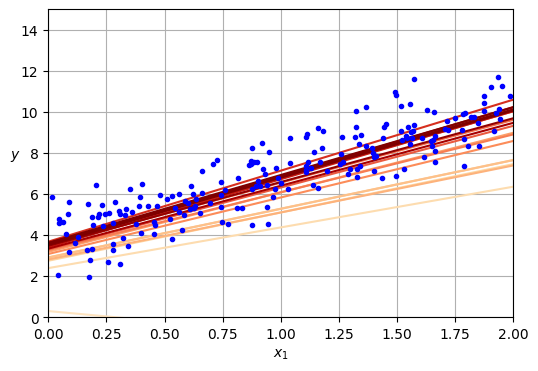

In [6]:
n_epochs = 50
t0, t1 = 5, 50  # 학습 스케줄 하이퍼파라미터

def learning_schedule(t):
    return t0 / (t + t1)

rng = np.random.default_rng(seed=42)
theta = rng.standard_normal((2, 1))  # 모델 파라미터를 랜덤하게 초기화

n_shown = 20  # 그래프에 표시할 스텝 수
plt.figure(figsize=(6, 4))
theta_path_sgd = []
for epoch in range(n_epochs):
    for iteration in range(m):
        if epoch == 0 and iteration < n_shown:
            y_predict = X_new_b @ theta
            color = mpl.colors.rgb2hex(plt.cm.OrRd(iteration / n_shown + 0.15))
            plt.plot(X_new, y_predict, color=color)

        random_index = rng.integers(m)
        xi = X_b[random_index : random_index + 1]
        yi = y[random_index : random_index + 1]
        gradients = 2 * xi.T @ (xi @ theta - yi)  # SGD 에서는 m으로 나누지 않습니다.
        eta = learning_schedule(epoch * m + iteration)  # 학습률
        theta = theta - eta * gradients
        theta_path_sgd.append(theta)  # 파라미터 경로 저장 (4.2.3 비교용)

print("y=", theta[1], "x + ", theta[0])  # y= [3.30748311] x +  [3.69826475]

plt.plot(X, y, "b.")
plt.xlabel("$x_1$")
plt.ylabel("$y$", rotation=0)
plt.axis([0, 2, 0, 15])
plt.grid()
plt.show()

사이킷런 `SGDRegressor`로 같은 모델을 훈련합니다.

In [7]:
from sklearn.linear_model import SGDRegressor

sgd_reg = SGDRegressor(max_iter=1000, tol=1e-5, penalty=None, eta0=0.01,
                       n_iter_no_change=100, random_state=42)
sgd_reg.fit(X, y.ravel())  # fit()이 1D 타깃을 기대하기 때문에 y.ravel()로 씁니다.
print("y=", sgd_reg.coef_, "x + ", sgd_reg.intercept_)  # y= [3.33054574] x +  [3.68899733]

y= [3.33054574] x +  [3.68899733]


### **4.2.3 미니배치 경사 하강법**

**미니배치**(20개)로 그레이디언트를 계산합니다. 아래 그림은 세 알고리즘이 파라미터 공간에서 움직인 경로입니다.

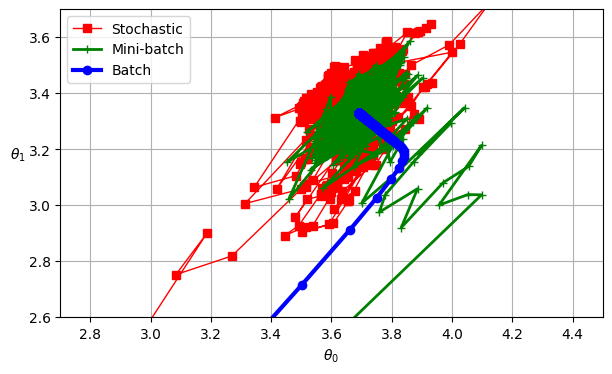

In [8]:
from math import ceil

n_epochs = 50
minibatch_size = 20
n_batches_per_epoch = ceil(m / minibatch_size)

rng = np.random.default_rng(seed=42)
theta = rng.standard_normal((2, 1))  # 모델 파라미터를 랜덤하게 초기화

t0, t1 = 200, 1000  # 학습 스케줄 하이퍼파라미터

def learning_schedule(t):
    return t0 / (t + t1)

theta_path_mgd = []
for epoch in range(n_epochs):
    shuffled_indices = rng.permutation(m)
    X_b_shuffled = X_b[shuffled_indices]
    y_shuffled = y[shuffled_indices]
    for iteration in range(0, n_batches_per_epoch):
        idx = iteration * minibatch_size
        xi = X_b_shuffled[idx : idx + minibatch_size]
        yi = y_shuffled[idx : idx + minibatch_size]
        gradients = 2 / minibatch_size * xi.T @ (xi @ theta - yi)
        eta = learning_schedule(epoch * n_batches_per_epoch + iteration)
        theta = theta - eta * gradients
        theta_path_mgd.append(theta)

# 세 알고리즘의 파라미터 경로 비교
theta_path_bgd = np.array(theta_path_bgd)
theta_path_sgd = np.array(theta_path_sgd)
theta_path_mgd = np.array(theta_path_mgd)

plt.figure(figsize=(7, 4))
plt.plot(theta_path_sgd[:, 0], theta_path_sgd[:, 1], "r-s", linewidth=1, label="Stochastic")
plt.plot(theta_path_mgd[:, 0], theta_path_mgd[:, 1], "g-+", linewidth=2, label="Mini-batch")
plt.plot(theta_path_bgd[:, 0], theta_path_bgd[:, 1], "b-o", linewidth=3, label="Batch")
plt.legend(loc="upper left")
plt.xlabel(r"$\theta_0$")
plt.ylabel(r"$\theta_1$   ", rotation=0)
plt.axis([2.7, 4.5, 2.6, 3.7])
plt.grid()
plt.show()

## **4.3 다항 회귀**

$y = 0.5x_1^2 + x_1 + 2 + \text{가우스 잡음}$으로 2차 비선형 데이터를 만듭니다.

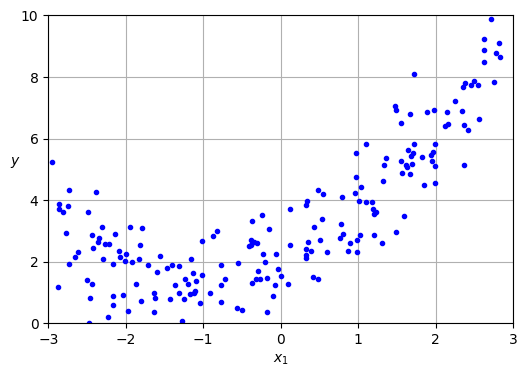

In [9]:
rng = np.random.default_rng(seed=42)
m = 200  # 샘플 개수
X = 6 * rng.random((m, 1)) - 3
y = 0.5 * X ** 2 + X + 2 + rng.standard_normal((m, 1))

plt.figure(figsize=(6, 4))
plt.plot(X, y, "b.")
plt.xlabel("$x_1$")
plt.ylabel("$y$", rotation=0)
plt.axis([-3, 3, 0, 10])
plt.grid()
plt.show()

`PolynomialFeatures(degree=2)`로 각 특성의 제곱을 새 특성으로 추가합니다.

In [10]:
from sklearn.preprocessing import PolynomialFeatures

poly_features = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly_features.fit_transform(X)
print(X[0])       # [1.64373629]
print(X_poly[0])  # [1.64373629 2.701869  ]

[1.64373629]
[1.64373629 2.701869  ]


확장된 특성에 `LinearRegression`을 훈련하면 원래 함수와 비슷한 $\hat{y} = 0.51x_1^2 + 1.11x_1 + 2.01$을 얻습니다.

y =

 0.5052698547174634 x² + 1.1102212625526895 x + 2.0054071887146327


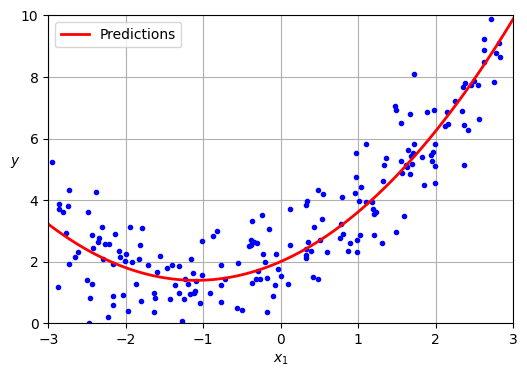

In [11]:
lin_reg = LinearRegression()
lin_reg.fit(X_poly, y)
print("y =", lin_reg.coef_[0][1], "x² +", lin_reg.coef_[0][0], "x +", lin_reg.intercept_[0])

X_new = np.linspace(-3, 3, 100).reshape(100, 1)
X_new_poly = poly_features.transform(X_new)
y_new = lin_reg.predict(X_new_poly)

plt.figure(figsize=(6, 4))
plt.plot(X, y, "b.")
plt.plot(X_new, y_new, "r-", linewidth=2, label="Predictions")
plt.xlabel("$x_1$")
plt.ylabel("$y$", rotation=0)
plt.legend(loc="upper left")
plt.axis([-3, 3, 0, 10])
plt.grid()

plt.show()

## **4.4 학습 곡선**

300차 다항 회귀는 훈련 데이터에 **과대적합**, 1차(직선)는 **과소적합**, 2차가 가장 잘 일반화됩니다.

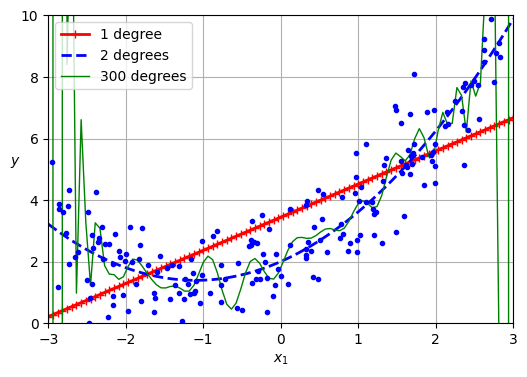

In [12]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# 1차(직선), 2차, 300차 다항 회귀 비교
plt.figure(figsize=(6, 4))

for style, width, degree in (("r-+", 2, 1), ("b--", 2, 2), ("g-", 1, 300)):
    polybig_features = PolynomialFeatures(degree=degree, include_bias=False)
    std_scaler = StandardScaler()
    lin_reg = LinearRegression()
    polynomial_regression = make_pipeline(polybig_features, std_scaler, lin_reg)
    polynomial_regression.fit(X, y)
    y_newbig = polynomial_regression.predict(X_new)
    label = f"{degree} degree{'s' if degree > 1 else ''}"
    plt.plot(X_new, y_newbig, style, label=label, linewidth=width)

plt.plot(X, y, "b.", linewidth=3)
plt.legend(loc="upper left")
plt.xlabel("$x_1$")
plt.ylabel("$y$", rotation=0)
plt.axis([-3, 3, 0, 10])
plt.grid()

plt.show()

`learning_curve()`로 선형 회귀의 학습 곡선을 그립니다. 두 곡선이 높은 오차에서 가까이 붙어 있으면 **과소적합**입니다.

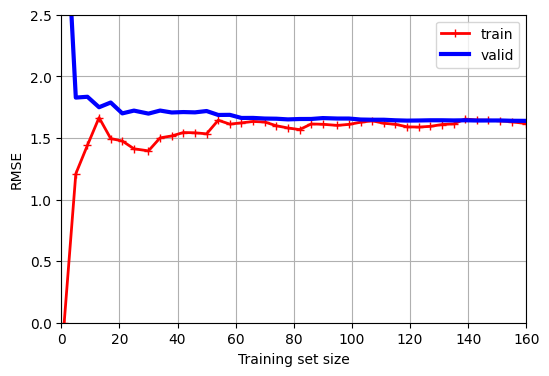

In [13]:
from sklearn.model_selection import learning_curve

train_sizes, train_scores, valid_scores = learning_curve(
    LinearRegression(), X, y, train_sizes=np.linspace(0.01, 1.0, 40), cv=5,
    scoring="neg_root_mean_squared_error")
train_errors = -train_scores.mean(axis=1)  # 점수는 음수 RMSE이므로 부호를 바꿈
valid_errors = -valid_scores.mean(axis=1)

plt.figure(figsize=(6, 4))
plt.plot(train_sizes, train_errors, "r-+", linewidth=2, label="train")
plt.plot(train_sizes, valid_errors, "b-", linewidth=3, label="valid")

plt.xlabel("Training set size")
plt.ylabel("RMSE")
plt.grid()
plt.legend(loc="upper right")
plt.axis([0, 160, 0, 2.5])
plt.show()

10차 다항 회귀의 학습 곡선: 훈련 오차가 훨씬 낮고 두 곡선 사이에 간격이 있으면 **과대적합**입니다.

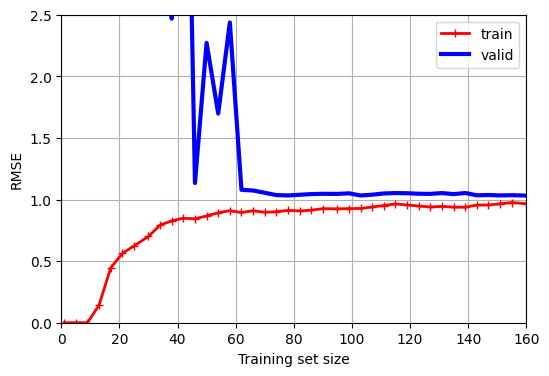

In [14]:
polynomial_regression = make_pipeline(PolynomialFeatures(degree=10, include_bias=False), LinearRegression())
train_sizes, train_scores, valid_scores = learning_curve(
    polynomial_regression, X, y, train_sizes=np.linspace(0.01, 1.0, 40), cv=5,
    scoring="neg_root_mean_squared_error")

train_errors = -train_scores.mean(axis=1)
valid_errors = -valid_scores.mean(axis=1)

plt.figure(figsize=(6, 4))
plt.plot(train_sizes, train_errors, "r-+", linewidth=2, label="train")
plt.plot(train_sizes, valid_errors, "b-", linewidth=3, label="valid")
plt.legend(loc="upper right")
plt.xlabel("Training set size")
plt.ylabel("RMSE")
plt.grid()
plt.axis([0, 160, 0, 2.5])
plt.show()

## **4.5 규제가 있는 선형 모델**

### **4.5.1 릿지 회귀(Ridge Regression)**

MSE에 가중치의 $\ell_2$ 노름 제곱을 규제항으로 더합니다. (편향 $\theta_0$은 규제하지 않음)

$$J(\boldsymbol{\theta}) = \text{MSE}(\boldsymbol{\theta}) + \frac{\alpha}{m} \sum_{i=1}^{n} \theta_i^2$$

잡음이 많은 선형 데이터에 여러 $\alpha$로 릿지 모델을 훈련합니다. (왼쪽: 선형, 오른쪽: 10차 다항 특성 + 스케일 조정) $\alpha$가 클수록 직선에 가까워집니다.

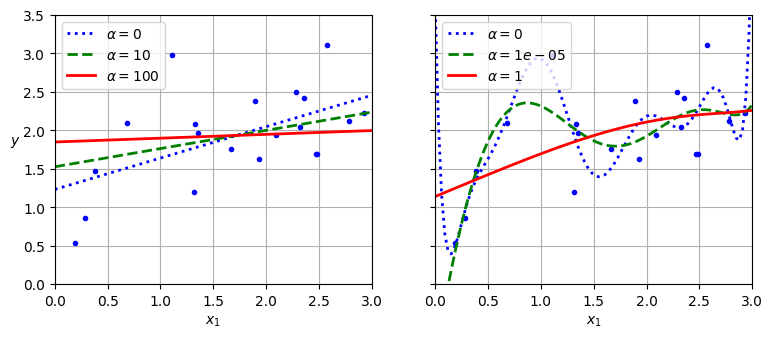

In [15]:
from sklearn.linear_model import Ridge

# 잡음이 많은 선형 데이터 생성
rng = np.random.default_rng(seed=42)
m = 20  # 샘플 개수
X = 3 * rng.random((m, 1))
y = 1 + 0.5 * X + rng.standard_normal((m, 1)) / 1.5
X_new = np.linspace(0, 3, 100).reshape(100, 1)

# alpha 값에 따른 모델 예측을 그리는 함수 (alpha=0이면 일반 선형 회귀)
def plot_model(model_class, polynomial, alphas, **model_kwargs):
    plt.plot(X, y, "b.", linewidth=3)
    for alpha, style in zip(alphas, ("b:", "g--", "r-")):
        if alpha > 0:
            model = model_class(alpha, **model_kwargs)
        else:
            model = LinearRegression()
        if polynomial:
            model = make_pipeline(PolynomialFeatures(degree=10, include_bias=False), StandardScaler(), model)
        model.fit(X, y)
        y_new_regul = model.predict(X_new)
        plt.plot(X_new, y_new_regul, style, linewidth=2, label=fr"$\alpha = {alpha}$")
    plt.legend(loc="upper left")
    plt.xlabel("$x_1$")
    plt.axis([0, 3, 0, 3.5])
    plt.grid()

plt.figure(figsize=(9, 3.5))
plt.subplot(121)
plot_model(Ridge, polynomial=False, alphas=(0, 10, 100), random_state=42)
plt.ylabel("$y$  ", rotation=0)
plt.subplot(122)
plot_model(Ridge, polynomial=True, alphas=(0, 10**-5, 1), random_state=42)
plt.gca().axes.yaxis.set_ticklabels([])
plt.show()

정규 방정식(숄레스키 분해)으로 릿지 회귀를 계산합니다.

In [16]:
ridge_reg = Ridge(alpha=0.1, solver="cholesky")
ridge_reg.fit(X, y)
print(ridge_reg.predict([[1.5]]))  # [1.84414523]

[1.84414523]


SGD에 $\ell_2$ 규제를 적용합니다. SGD는 규제항을 $m$으로 나누지 않으므로 `Ridge(alpha=0.1)`과 맞추려고 `alpha=0.1 / m`을 사용합니다.

In [17]:
sgd_reg = SGDRegressor(penalty="l2", alpha=0.1 / m, tol=None, max_iter=1000,
                       eta0=0.01, random_state=42)
sgd_reg.fit(X, y.ravel())  # fit()은 1D 타깃을 기대하므로 y.ravel()로 씁니다.
print(sgd_reg.predict([[1.5]]))  # [1.83659707]

[1.83659707]


### **4.5.2 라쏘 회귀(Lasso Regression)**

$\ell_2$ 노름 대신 가중치의 $\ell_1$ 노름을 규제항으로 사용합니다. 덜 중요한 특성의 가중치를 0으로 만듭니다.

$$J(\boldsymbol{\theta}) = \text{MSE}(\boldsymbol{\theta}) + 2\alpha \sum_{i=1}^{n} |\theta_i|$$

같은 데이터에 라쏘 모델을 훈련합니다. 오른쪽 점선($\alpha=0.01$)은 고차 항의 가중치가 0이 되어 3차 방정식처럼 보입니다.

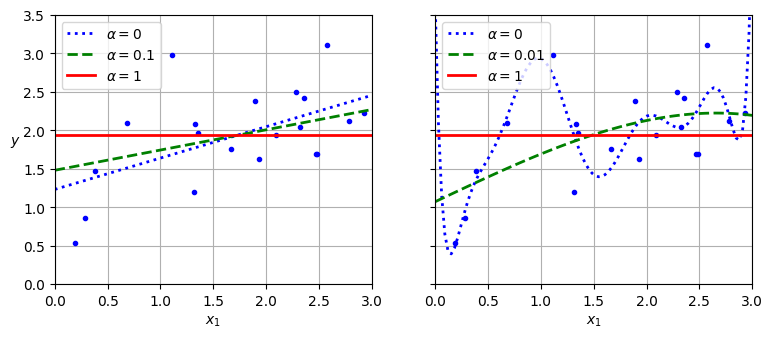

In [18]:
from sklearn.linear_model import Lasso

plt.figure(figsize=(9, 3.5))
plt.subplot(121)
plot_model(Lasso, polynomial=False, alphas=(0, 0.1, 1), random_state=42)
plt.ylabel("$y$  ", rotation=0)
plt.subplot(122)
plot_model(Lasso, polynomial=True, alphas=(0, 1e-2, 1), random_state=42)
plt.gca().axes.yaxis.set_ticklabels([])
plt.show()

$\ell_1$ / $\ell_2$ 페널티와 라쏘 / 릿지 비용 함수의 등고선, 그리고 경사 하강법의 경로를 비교합니다. (위: 라쏘, 아래: 릿지)

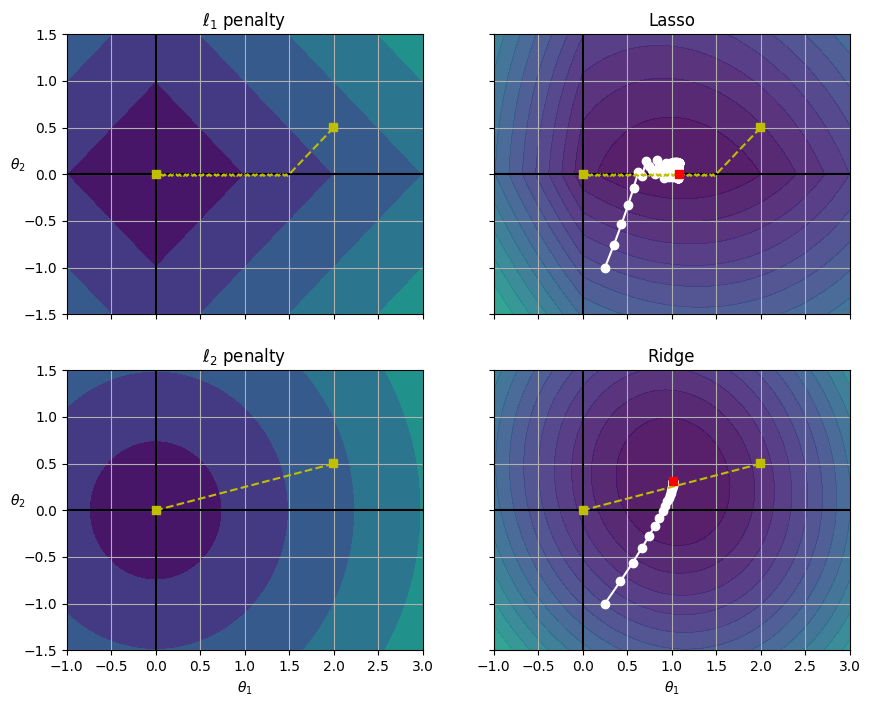

In [19]:
# 파라미터 공간(θ1, θ2) 격자
t1a, t1b, t2a, t2b = -1, 3, -1.5, 1.5

t1s = np.linspace(t1a, t1b, 500)
t2s = np.linspace(t2a, t2b, 500)
t1, t2 = np.meshgrid(t1s, t2s)
T = np.c_[t1.ravel(), t2.ravel()]
# 간단한 훈련 세트 (규제가 없을 때 최적점: θ1=2, θ2=0.5)
Xr = np.array([[1, 1], [1, -1], [1, 0.5]])
yr = 2 * Xr[:, :1] + 0.5 * Xr[:, 1:]

# J: MSE, N1: ℓ1 노름, N2: ℓ2 노름
J = (1 / len(Xr) * ((T @ Xr.T - yr.T) ** 2).sum(axis=1)).reshape(t1.shape)
N1 = np.linalg.norm(T, ord=1, axis=1).reshape(t1.shape)
N2 = np.linalg.norm(T, ord=2, axis=1).reshape(t1.shape)

t_min_idx = np.unravel_index(J.argmin(), J.shape)
t1_min, t2_min = t1[t_min_idx], t2[t_min_idx]

t_init = np.array([[0.25], [-1]])

# 규제항(l1, l2)을 포함한 배치 경사 하강법 경로
def bgd_path(theta, X, y, l1, l2, core=1, eta=0.05, n_iterations=200):
    path = [theta]
    for iteration in range(n_iterations):
        gradients = (core * 2 / len(X) * X.T @ (X @ theta - y)
                     + l1 * np.sign(theta) + l2 * theta)
        theta = theta - eta * gradients
        path.append(theta)
    return np.array(path)

fig, axes = plt.subplots(2, 2, sharex=True, sharey=True, figsize=(10.1, 8))

for i, N, l1, l2, title in ((0, N1, 2.0, 0, "Lasso"), (1, N2, 0, 2.0, "Ridge")):
    JR = J + l1 * N1 + l2 * 0.5 * N2 ** 2

    tr_min_idx = np.unravel_index(JR.argmin(), JR.shape)
    t1r_min, t2r_min = t1[tr_min_idx], t2[tr_min_idx]

    levels = np.exp(np.linspace(0, 1, 20)) - 1
    levelsJ = levels * (J.max() - J.min()) + J.min()
    levelsJR = levels * (JR.max() - JR.min()) + JR.min()
    levelsN = np.linspace(0, N.max(), 10)

    path_J = bgd_path(t_init, Xr, yr, l1=0, l2=0)
    path_JR = bgd_path(t_init, Xr, yr, l1, l2)
    path_N = bgd_path(theta=np.array([[2.0], [0.5]]), X=Xr, y=yr, l1=np.sign(l1) / 3, l2=np.sign(l2), core=0)
    ax = axes[i, 0]
    ax.grid()
    ax.axhline(y=0, color="k")
    ax.axvline(x=0, color="k")
    ax.contourf(t1, t2, N / 2.0, levels=levelsN)
    ax.plot(path_N[:, 0], path_N[:, 1], "y--")
    ax.plot(0, 0, "ys")
    ax.plot(t1_min, t2_min, "ys")
    ax.set_title(fr"$\ell_{i + 1}$ penalty")
    ax.axis([t1a, t1b, t2a, t2b])
    if i == 1:
        ax.set_xlabel(r"$\theta_1$")
    ax.set_ylabel(r"$\theta_2$", rotation=0)

    ax = axes[i, 1]
    ax.grid()
    ax.axhline(y=0, color="k")
    ax.axvline(x=0, color="k")
    ax.contourf(t1, t2, JR, levels=levelsJR, alpha=0.9)
    ax.plot(path_JR[:, 0], path_JR[:, 1], "w-o")
    ax.plot(path_N[:, 0], path_N[:, 1], "y--")
    ax.plot(0, 0, "ys")
    ax.plot(t1_min, t2_min, "ys")
    ax.plot(t1r_min, t2r_min, "rs")
    ax.set_title(title)
    ax.axis([t1a, t1b, t2a, t2b])
    if i == 1:
        ax.set_xlabel(r"$\theta_1$")
plt.show()

사이킷런 `Lasso` 클래스 예제입니다. (`SGDRegressor(penalty="l1", alpha=0.1)`도 가능)

In [20]:
lasso_reg = Lasso(alpha=0.1)
lasso_reg.fit(X, y)
print(lasso_reg.predict([[1.5]]))  # [1.87550211]

[1.87550211]


### **4.5.3 엘라스틱넷(Elastic Net)**

릿지와 라쏘의 규제항을 혼합 비율 $r$(`l1_ratio`)로 섞습니다. ($r=0$이면 릿지, $r=1$이면 라쏘)

사이킷런 `ElasticNet` 예제입니다.

In [21]:
from sklearn.linear_model import ElasticNet

elastic_net = ElasticNet(alpha=0.1, l1_ratio=0.5)
elastic_net.fit(X, y)
print(elastic_net.predict([[1.5]]))  # [1.8645014]

[1.8645014]


### **4.5.4 조기 종료(Early Stopping)**

90차 다항 회귀를 `partial_fit()`으로 한 에포크씩 훈련하며 검증 RMSE가 가장 낮은 모델을 `deepcopy()`로 저장합니다. 검증 오차가 다시 올라가기 시작하면 과대적합입니다.

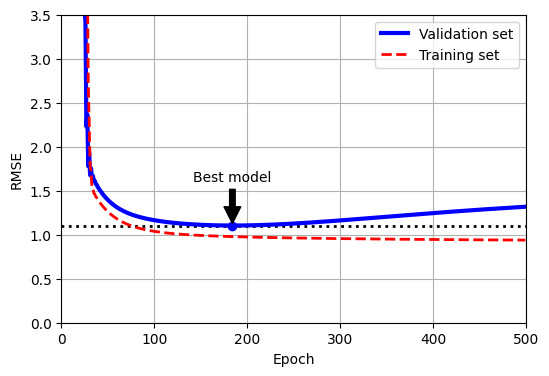

In [22]:
from copy import deepcopy
from sklearn.metrics import root_mean_squared_error

rng = np.random.default_rng(seed=42)
m = 200  # 샘플 개수
X = 6 * rng.random((m, 1)) - 3
y = 0.5 * X ** 2 + X + 2 + rng.standard_normal((m, 1))
# 앞쪽 절반은 훈련 세트, 뒤쪽 절반은 검증 세트
X_train, y_train = X[: m // 2], y[: m // 2, 0]
X_valid, y_valid = X[m // 2 :], y[m // 2 :, 0]

# 90차 다항 특성 + 스케일 조정 (과대적합되기 쉬운 복잡한 모델)
preprocessing = make_pipeline(PolynomialFeatures(degree=90, include_bias=False), StandardScaler())
X_train_prep = preprocessing.fit_transform(X_train)
X_valid_prep = preprocessing.transform(X_valid)
sgd_reg = SGDRegressor(penalty=None, eta0=0.002, random_state=42)
n_epochs = 500
best_valid_rmse = float('inf')
train_errors, val_errors = [], []

for epoch in range(n_epochs):
    sgd_reg.partial_fit(X_train_prep, y_train)  # 점진적 학습 (한 에포크)
    y_valid_predict = sgd_reg.predict(X_valid_prep)
    val_error = root_mean_squared_error(y_valid, y_valid_predict)
    if val_error < best_valid_rmse:
        best_valid_rmse = val_error
        best_model = deepcopy(sgd_reg)  # 검증 오차가 가장 낮은 모델 저장

    y_train_predict = sgd_reg.predict(X_train_prep)
    train_error = root_mean_squared_error(y_train, y_train_predict)
    val_errors.append(val_error)
    train_errors.append(train_error)

best_epoch = np.argmin(val_errors)
plt.figure(figsize=(6, 4))
plt.annotate('Best model', xy=(best_epoch, best_valid_rmse),
             xytext=(best_epoch, best_valid_rmse + 0.5), ha="center",
             arrowprops=dict(facecolor='black', shrink=0.05))
plt.plot([0, n_epochs], [best_valid_rmse, best_valid_rmse], "k:", linewidth=2)
plt.plot(val_errors, "b-", linewidth=3, label="Validation set")
plt.plot(best_epoch, best_valid_rmse, "bo")
plt.plot(train_errors, "r--", linewidth=2, label="Training set")
plt.legend(loc="upper right")
plt.xlabel("Epoch")
plt.ylabel("RMSE")
plt.axis([0, n_epochs, 0, 3.5])
plt.grid()
plt.show()

## **4.6 로지스틱 회귀(Logistic Regression)**

### **4.6.1 확률 추정(Estimating Probabilities)**

입력 특성의 가중치 합을 계산한 뒤 **로지스틱 함수(시그모이드)** 를 적용해 0~1 사이의 확률을 출력합니다.

$$\hat{p} = h_{\boldsymbol{\theta}}(\mathbf{x}) = \sigma(\boldsymbol{\theta}^{\mathrm{T}} \mathbf{x}), \qquad \sigma(t) = \frac{1}{1 + e^{-t}}$$

로지스틱(시그모이드) 함수 그래프: $t < 0$이면 $\sigma(t) < 0.5$, $t \ge 0$이면 $\sigma(t) \ge 0.5$

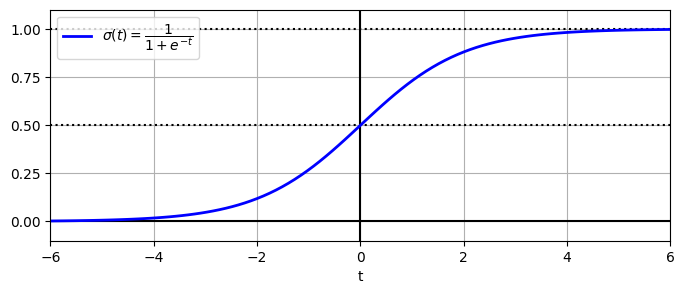

In [23]:
lim = 6
t = np.linspace(-lim, lim, 100)
sig = 1 / (1 + np.exp(-t))

plt.figure(figsize=(8, 3))
plt.plot([-lim, lim], [0, 0], "k-")
plt.plot([-lim, lim], [0.5, 0.5], "k:")
plt.plot([-lim, lim], [1, 1], "k:")
plt.plot([0, 0], [-1.1, 1.1], "k-")
plt.plot(t, sig, "b-", linewidth=2, label=r"$\sigma(t) = \dfrac{1}{1 + e^{-t}}$")
plt.xlabel("t")
plt.legend(loc="upper left")
plt.axis([-lim, lim, -0.1, 1.1])
plt.gca().set_yticks([0, 0.25, 0.5, 0.75, 1])
plt.grid()
plt.show()

### **4.6.2 훈련과 비용 함수**

양성 샘플은 높은 확률로, 음성 샘플은 낮은 확률로 추정하도록 **로그 손실(log loss)** 을 최소화합니다.

$$J(\boldsymbol{\theta}) = -\frac{1}{m} \sum_{i=1}^{m} \left[ y^{(i)} \log(\hat{p}^{(i)}) + (1 - y^{(i)}) \log(1 - \hat{p}^{(i)}) \right]$$

정규 방정식 같은 해는 없지만 볼록 함수이므로 경사 하강법으로 전역 최솟값을 찾을 수 있습니다. (코드 없음)

### **4.6.3 결정 경계(Decision Boundaries)**

붓꽃(iris) 데이터셋을 데이터프레임으로 불러옵니다. (3개 품종 × 150개 샘플)

In [24]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
print(list(iris))
print(iris.data.head(3))
print(iris.target.head(3))
print(iris.target_names)

['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module']
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
0    0
1    0
2    0
Name: target, dtype: int64
['setosa' 'versicolor' 'virginica']


꽃잎 너비 하나로 **Iris virginica**인지 판별하는 로지스틱 회귀를 훈련하고, 0~3cm 구간의 추정 확률을 그립니다.

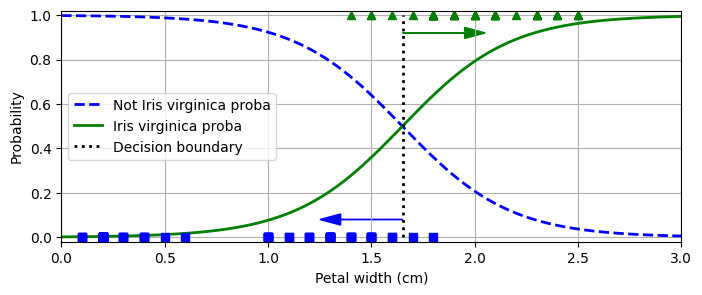

In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

X = iris.data[["petal width (cm)"]].values
y = iris.target_names[iris.target] == 'virginica'
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

log_reg = LogisticRegression(random_state=42)
log_reg.fit(X_train, y_train)

X_new = np.linspace(0, 3, 1000).reshape(-1, 1)
y_proba = log_reg.predict_proba(X_new)
decision_boundary = X_new[y_proba[:, 1] >= 0.5][0, 0]  # 양성 확률이 처음 50% 이상이 되는 지점

plt.figure(figsize=(8, 3))
plt.plot(X_new, y_proba[:, 0], "b--", linewidth=2, label="Not Iris virginica proba")
plt.plot(X_new, y_proba[:, 1], "g-", linewidth=2, label="Iris virginica proba")
plt.plot([decision_boundary, decision_boundary], [0, 1], "k:", linewidth=2, label="Decision boundary")

plt.arrow(x=decision_boundary, y=0.08, dx=-0.3, dy=0, head_width=0.05, head_length=0.1, fc="b", ec="b")
plt.arrow(x=decision_boundary, y=0.92, dx=0.3, dy=0, head_width=0.05, head_length=0.1, fc="g", ec="g")
plt.plot(X_train[y_train == 0], y_train[y_train == 0], "bs")
plt.plot(X_train[y_train == 1], y_train[y_train == 1], "g^")
plt.xlabel("Petal width (cm)")
plt.ylabel("Probability")
plt.legend(loc="center left")
plt.axis([0, 3, -0.02, 1.02])
plt.grid()
plt.show()

결정 경계는 약 1.65cm입니다. 이보다 크면 virginica, 작으면 아니라고 예측합니다.

In [26]:
print(decision_boundary)  # 1.6516516516516517
print(log_reg.predict([[1.7], [1.5]]))  # [ True False]

1.6516516516516517
[ True False]


꽃잎 길이와 너비 두 특성으로 훈련합니다. 점선이 결정 경계(50%)이고, 나란한 직선들이 확률 등고선입니다.

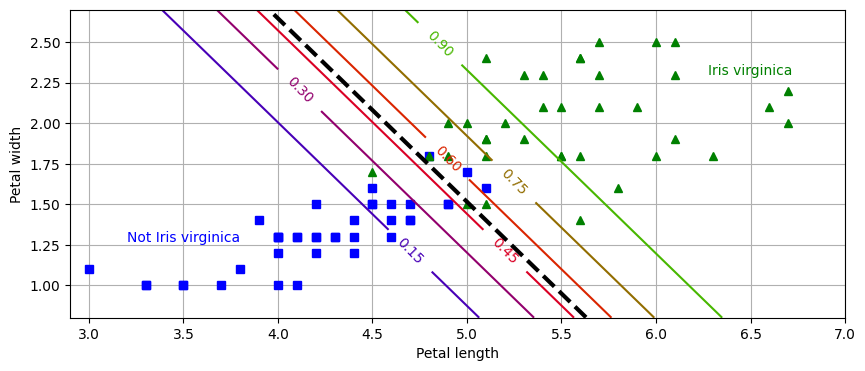

In [27]:
X = iris.data[["petal length (cm)", "petal width (cm)"]].values
y = iris.target_names[iris.target] == 'virginica'
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

log_reg = LogisticRegression(C=2, random_state=42)
log_reg.fit(X_train, y_train)

x0, x1 = np.meshgrid(np.linspace(2.9, 7, 500).reshape(-1, 1), np.linspace(0.8, 2.7, 200).reshape(-1, 1))
X_new = np.c_[x0.ravel(), x1.ravel()]
y_proba = log_reg.predict_proba(X_new)
zz = y_proba[:, 1].reshape(x0.shape)

# 결정 경계(확률 50%): θ0 + θ1·x0 + θ2·x1 = 0 을 x1에 대해 풂
left_right = np.array([2.9, 7])
boundary = -((log_reg.coef_[0, 0] * left_right + log_reg.intercept_[0]) / log_reg.coef_[0, 1])

plt.figure(figsize=(10, 4))
plt.plot(X_train[y_train == 0, 0], X_train[y_train == 0, 1], "bs")
plt.plot(X_train[y_train == 1, 0], X_train[y_train == 1, 1], "g^")
contour = plt.contour(x0, x1, zz, cmap=plt.cm.brg)
plt.clabel(contour, inline=1)
plt.plot(left_right, boundary, "k--", linewidth=3)
plt.text(3.5, 1.27, "Not Iris virginica", color="b", ha="center")
plt.text(6.5, 2.3, "Iris virginica", color="g", ha="center")
plt.xlabel("Petal length")
plt.ylabel("Petal width")
plt.axis([2.9, 7, 0.8, 2.7])
plt.grid()
plt.show()

### **4.6.4 소프트맥스 회귀(Softmax Regression)**

클래스마다 점수 $s_k(\mathbf{x}) = (\boldsymbol{\theta}^{(k)})^{\mathrm{T}} \mathbf{x}$를 계산하고, 소프트맥스 함수로 확률을 추정합니다.

$$\hat{p}_k = \frac{\exp(s_k(\mathbf{x}))}{\sum_{j=1}^{K} \exp(s_j(\mathbf{x}))}$$

클래스가 3개이면 `LogisticRegression`이 자동으로 소프트맥스 회귀를 사용합니다. 꽃잎 길이 5cm, 너비 2cm인 붓꽃은 96% 확률로 virginica입니다.

In [28]:
X = iris.data[["petal length (cm)", "petal width (cm)"]].values
y = iris["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

softmax_reg = LogisticRegression(C=30, random_state=42)
softmax_reg.fit(X_train, y_train)

print(softmax_reg.predict([[5, 2]]))  # [2] → virginica
print(softmax_reg.predict_proba([[5, 2]]).round(2))  # [[0.   0.04 0.96]]

[2]
[[0.   0.04 0.96]]


배경색은 예측 클래스(결정 경계는 모두 선형), 등고선은 versicolor 클래스의 확률입니다.

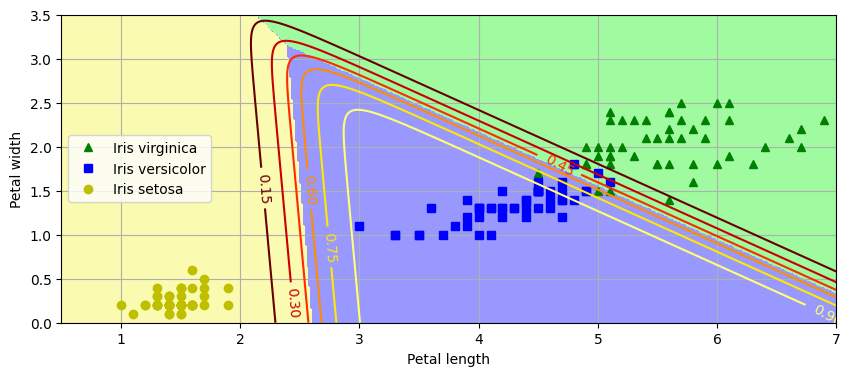

In [29]:
from matplotlib.colors import ListedColormap

custom_cmap = ListedColormap(["#fafab0", "#9898ff", "#a0faa0"])

x0, x1 = np.meshgrid(np.linspace(0, 8, 500).reshape(-1, 1), np.linspace(0, 3.5, 200).reshape(-1, 1))
X_new = np.c_[x0.ravel(), x1.ravel()]

y_proba = softmax_reg.predict_proba(X_new)
y_predict = softmax_reg.predict(X_new)

zz1 = y_proba[:, 1].reshape(x0.shape)  # versicolor 클래스 확률 (등고선)
zz = y_predict.reshape(x0.shape)  # 예측 클래스 (배경색)

plt.figure(figsize=(10, 4))
plt.plot(X[y == 2, 0], X[y == 2, 1], "g^", label="Iris virginica")
plt.plot(X[y == 1, 0], X[y == 1, 1], "bs", label="Iris versicolor")
plt.plot(X[y == 0, 0], X[y == 0, 1], "yo", label="Iris setosa")

plt.contourf(x0, x1, zz, cmap=custom_cmap)
contour = plt.contour(x0, x1, zz1, cmap="hot")
plt.clabel(contour, inline=1)
plt.xlabel("Petal length")
plt.ylabel("Petal width")
plt.legend(loc="center left")
plt.axis([0.5, 7, 0, 3.5])
plt.grid()
plt.show()